## 케라스 (Keras)
- 딥러닝 모델을 쉽고 빠르게 만들 수 있도록 도와주는 고수준 딥러닝 라이브러리
- 텐서플로(Tensorflow) 위에서 동작하며, 복잡한 수학적 계산을 직접 구현하지 않고 모델 구성 및 학습 가능
- 작업 흐름
1. 모델 정의
2. 컴파일
3. 학습

###환경 준비 : tensorflow 설치


In [4]:
import os
import tensorflow as tf

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

tf.__version__

'2.15.1'

In [5]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#from tensorflow.keras import Sequential          # 표준으로 사용되는 방식
from keras import Sequential                      # 공식 권장 방식 -> 하나로 통일하여 사용할 것
from keras.layers import Dense, Dropout, Input
from keras.callbacks import EarlyStopping

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score

import _ml
from _style import setup

SEED = _ml.SEED
setup()

print("준비 완료")

준비 완료


---

머신러닝으로는 `오늘 오를까 ? `를 예측했고, 결과는 AUC 0.5 부근으로 사실상 랜덤
신호 없는 문제로는 **알고리즘이 잘 동작하는지조차 확인할 수 없었음**

딥러닝으로는 `오늘 거래량이 최근 20일 평균보다 많을까>`를 예측해보기 (거래량 급증 여부)

거래량은 한 번 몰리면 며칠 이어지는 성질이 있어 **어느정도 예측이 가능**

In [6]:
def load_datasets():
    """
        거래량 급증 예측용 데이터 셋을 만들어서 반환

        - 기존 피처(_ml.FEATURES) 7개에 2개를 추가 (volume_prev, 전일 거래량) (close_prev, 전일 종가)
        - 정답 (surge) : 오늘 거래량이 직전 20일 평균 거래량보다 크면 1, 아니면 0
    """
    # 기존 데이터셋에서 피처 2개 추가
    base = _ml.build_dataset().sort_values(["code", "date"])

    base["volume_prev"] = base.groupby("code")["volume"].shift(1)
    base["close_prev"] = base.groupby("code")["close"].shift(1)

    # 원본 데이터에서 계산 후 정답 추가
    raw = _ml.load_merged().sort_values(["code", "date"])

    # - 정답 : 오늘 거래량 -> 직전 20일 평균 거래량

    # 직전 20일 평균 거래량
    raw["vol_ma20_prev"] = raw.groupby("code")["volume"].transform(lambda s: s.rolling(20).mean().shift(1))

    # 정답 (surge) : 거래량 급증 여부 (1: 급증, 0: 아님)
    raw["surge"] = (raw["volume"] > raw["vol_ma20_prev"]).astype("int8")

    df = base.merge(raw[["code", "date", "surge"]], how="left", on=["code", "date"])
    return df.dropna(subset=["volume_prev", "close_prev", "surge"]).reset_index(drop=True)

df = load_datasets()
FEATURES = _ml.FEATURES + ["volume_prev", "close_prev"]

print(f"데이터 {len(df):,}행, 피처 {len(FEATURES)}개")
print(f"급증 비율 : {df['surge'].mean():.3f}")
print(f"피처 : {FEATURES}")


데이터 87,360행, 피처 9개
급증 비율 : 0.366
피처 : ['ret_1d', 'ret_5d', 'ma5_ratio', 'ma20_ratio', 'vol20', 'volume_ratio', 'range_pct', 'volume_prev', 'close_prev']


In [7]:
# 시계열 데이터는 시간순으로 분할 (데이터 분리 -> 훈련용, 검증용)
train, test, cutoff = _ml.time_split(df, test_size=0.2)

# X(피처, 입력), y(타깃, 정답)분리
X_train = train[FEATURES].to_numpy("float32")
y_train = train["surge"].to_numpy("float32")

X_test = test[FEATURES].to_numpy("float32")
y_test = test["surge"].to_numpy("float32")

print(f"분할 기준일 : {cutoff.date()}")
print(f"학습 : {X_train.shape} 검증 : {X_test.shape}")

scale = pd.DataFrame({
    "평균":X_train.mean(axis=0),
    "표준편차":X_train.std(axis=0),
    "최대":X_train.max(axis=0)
},index=FEATURES)

print()
print(scale.to_string(float_format=lambda v: f"{v:>18,.4f}"))
print(f"\n표준편차 최대/최소 = {scale['표준편차'].max() / scale['표준편차'].min():,.0f} 배 차이")

분할 기준일 : 2026-01-16
학습 : (69960, 9) 검증 : (17400, 9)

                             평균               표준편차                 최대
ret_1d                  -0.0003             0.0263             0.2755
ret_5d                  -0.0014             0.0613             0.4257
ma5_ratio                0.9989             0.0298             1.2395
ma20_ratio               0.9950             0.0687             1.4317
vol20                    0.0243             0.0101             0.0677
volume_ratio             1.0016             0.9528            15.5041
range_pct                4.3529             2.0448            33.7038
volume_prev        577,769.7500     1,555,611.6250    71,626,144.0000
close_prev          46,903.8906        59,168.6992       552,685.0000

표준편차 최대/최소 = 154,746,496 배 차이


현재 표준 편차가 **1억 배 이상** 차이나는 상태로 확인됨\
이 상태로 신경망에 입력하면, 거대한 피처가 기울기 계산을 독점하게 될 것
--> 학습이 제대로 되지 않기 때문에, 표준화 또는 정규화의 전처리가 필수적임

---



### 딥러닝의 3단계 : 모델 정의 -> 컴파일 -> 학습

1. 모델 정의 : 어떤 층을 어떻게 쌓을 것인가?
2. 컴파일 : 무엇을 최소화하고 어떻게 학습할 것인가?
3. 학습 : 데이터를 넣고 반복

케라스(Keras)를 사용하면 통일된 형태로 간단하게 구현이 가능


In [8]:
def build_model(n_features, hidden=(64, 32), dropout=0.0):
    """
        이진 분류용 신경망 생성
        
        매개변수 
            n_features : 입력 피처 개수
            hidden     : 은닉층 뉴런수, 튜플 길이가 은닉층 개수 (기본 64, 32 두 층)
            dropout    : 0보다 큰 경우 각 은닉층 뒤에 Dropout 추가 (비율, 0~1)
        반환값
            model      : 컴파일까지 끝난 Sequential 모델
    """

    # 가중치 초기값 고정
    tf.keras.utils.set_random_seed(SEED)

    layers = [ Input(shape=(n_features,))] # 입력층

    for units in hidden:
        layers.append(
            Dense(units, activation="relu") # 은닉층
        )
        if dropout > 0:
            layers.append( Dropout(dropout))

    layers.append(Dense(1, activation="sigmoid")) # 이진분류 

    model = Sequential(layers) #[1] 모델 정의 

    # [2] 컴파일
    model.compile(
        optimizer="adam",               #파라미터별 학습 속도 적응적으로 조절하는 최적화 방법
        loss="binary_crossentropy",     #손실함수 -> 오차 측정 기준
        metrics=["accuracy"]            #정확도(accurcy0기록 설정
    )
    return model

model = build_model(len(FEATURES))
model.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                640       
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 2753 (10.75 KB)
Trainable params: 2753 (10.75 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


**Total params** : Dense 층의 파라미터는 (입력개수 * 뉴런개수) + 뉴런개수(편향)임

dense 9X64+64 = 640\
dense_1 64x32+32 = 2080\
dense_2 32X1+1 = 33\
= 2753



학습 곡선 그리는 함수 정의


In [9]:
def plot_history(hist, title, ax=None, ylim=None):
    """
        학습 곡선 그리는 함수 
        
        매개변수 
            hist : model.fit()이 반환한 history 객체
            title : 차트 제목
            ax : 그래프 그릴 영역 객체(Axes). None인 경우 새로 생성
            ylim : y축 범위 (최솟값, 최댓값).
              
              
        반환값
            ax  : 학습 곡선이 그려진 그래프 객체 (Axes)

    """

    if ax is None:
        _, ax = plt.subplots(figsize=(8,4))

    if ylim: 
        ax.set_ylim(*ylim)    

    # loss : 훈련 데이터 오차
    # val_loss : 검증 데이터 오차

    epochs = range(1, len(hist.history['loss']) +1)

    ax.plot(epochs, hist.history['loss'], label="train", lw=1.6)
    ax.plot(epochs, hist.history['val_loss'], label="validation", lw=1.6)

   # 검증 손실이 가장 낮았던 지점
    best = int(np.argmin(hist.history['val_loss'])) + 1     

    ax.axvline(best, color="gray", ls=":", lw=1)

    ax.set(xlabel="에포크", ylabel="손실", title=title)
    ax.legend()

    return ax

def evaluate(name,model,X,y,scaler=None):
    """
        주어진 데이터(x,y)에 대한 모델 성능을 한줄로 출력

        매개변수
            name  : 출력할 모델 이름
            model : 학습된 모델
            x     : 입력 피처. (scaler 사용 시 스케일 전 원본 값을 전달해야 함)
            y     : 정답 타깃
            scaler: 학습 데이터로 fit된 스케일러 (None이면 X를 그대로 사용)

        반환값
            auc   : ROC AUC(float)

        출력
            AUC와 정확도 (출력에시: {name} AUC {auc} 정확도 {auc})        
    """

    Xe = X if scaler is None else scaler.transform(X)

    model.predict(Xe)

    prob = model.predict(Xe, verbose=0).ravel()

    auc = roc_auc_score(y, prob)
    acc = accuracy_score(y, (prob >= 0.5).astype(int))

    print(f"{name:<28} AUC {auc:.4f} 정확도 {acc:.4f}")
    return auc


 

스케일링 없이 학습

원본 피처를 그대로 학습(거래량은 수천만, 등락률 0.0x임)

In [10]:
#검증 구간 만들기
order = np.argsort( train['date'].to_numpy(), kind="stable")

n_val = int(len(order) * 0.2)
fit_idx, val_idx = order[:-n_val], order[-n_val:]

X_fit, y_fit = X_train[fit_idx], y_train[fit_idx]
X_val, y_val = X_train[val_idx], y_train[val_idx]

print(f"학습 : {X_fit.shape} 검증 : {X_val.shape}")
print(f"검증 구간 시작일 : {train['date'].iloc[val_idx].min()}")


학습 : (55968, 9) 검증 : (13992, 9)
검증 구간 시작일 : 2025-08-07 00:00:00


In [11]:
def print_history(hist, digits=4):
    """
        학습 기록을 최대 10줄로 줄려서 출력하는 함수

        매개변수
            hist : fit() 후 전달받은 History 객체
            digits : 출력할 때 단위 옵션 (ex. .2f . 3f)
    """
    loss, val_loss = hist.history['loss'], hist.history['val_loss']

    step = max(1, len(loss) // 10)
    print("epoch    train_loss      val_loss")
    for i in range(0, len(loss), step):
        print(f"{i + 1:>5} {loss[i]:>14,.{digits}f} {val_loss[i]:>12,.{digits}f}")

In [12]:
t0 = time.time()

model_raw = build_model(len(FEATURES))
hist_raw = model_raw.fit(
    X_fit, y_fit,
    epochs=20,
    batch_size=512,
    validation_data= (X_val, y_val),
    shuffle=False,
    verbose=0, #출력옵션 (출력 끔)

)

print(f"학습 시간 : {time.time() - t0:.0f}초")



학습 시간 : 3초


**학습된 패턴**
- 손실이 처음부터 ** 수백 ~ 수천 ** 단위 (정상적이라면 0.6~7 근처에서 시작될 것)
- train/val 손실이 ** 줄었다 늘었다를 반복하며 안정적으로 내려가지 않고 있음
 
--> 과적합보다는 학습 불안정(발산)임. 과적함은 train은 계속 내려가는데, val만 올라가는 상태일 때


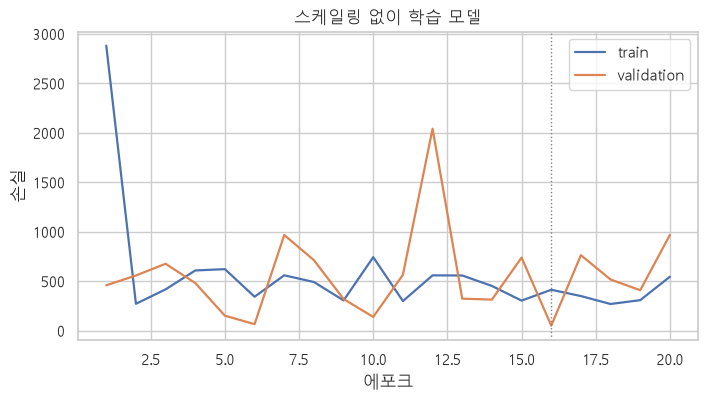

544/544 [==============================] - 0s 477us/step
스케일링 없이 학습 모델                AUC 0.5031 정확도 0.6253
AUC 0.50


In [13]:
plot_history(hist_raw, "스케일링 없이 학습 모델")
plt.show()

auc_raw = evaluate("스케일링 없이 학습 모델", model_raw, X_test, y_test)
print(f"AUC { auc_raw:.2f}")

---

###스케일링 후 학습\
StandardScaler로 모든 피처를 평균 0, 표준편차 1로 맞춰주기

In [14]:
scaler = StandardScaler().fit(X_fit)

X_fit_s = scaler.transform(X_fit)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print(
    pd.DataFrame({"평균": X_fit_s.mean(axis=0).round(3),
                  "표준편차": X_fit_s.std(axis=0).round(3)}, index=FEATURES)
)

               평균  표준편차
ret_1d       -0.0   1.0
ret_5d        0.0   1.0
ma5_ratio    -0.0   1.0
ma20_ratio   -0.0   1.0
vol20         0.0   1.0
volume_ratio  0.0   1.0
range_pct     0.0   1.0
volume_prev  -0.0   1.0
close_prev   -0.0   1.0


In [15]:
t0 = time.time()

model_scaled = build_model(len(FEATURES))
hist_scaled = model_scaled.fit(
    X_fit_s, y_fit, 
    epochs=20,
    batch_size=512,
    validation_data=(X_val_s, y_val),
    shuffle=False,
    verbose=0
)

print(f"학습 시간 : {time.time() - t0:.0f}초")
print_history(hist_scaled)

학습 시간 : 3초
epoch    train_loss      val_loss
    1         0.6526       0.6417
    3         0.6323       0.6258
    5         0.6284       0.6221
    7         0.6266       0.6205
    9         0.6255       0.6195
   11         0.6246       0.6188
   13         0.6239       0.6184
   15         0.6233       0.6181
   17         0.6228       0.6179
   19         0.6223       0.6177


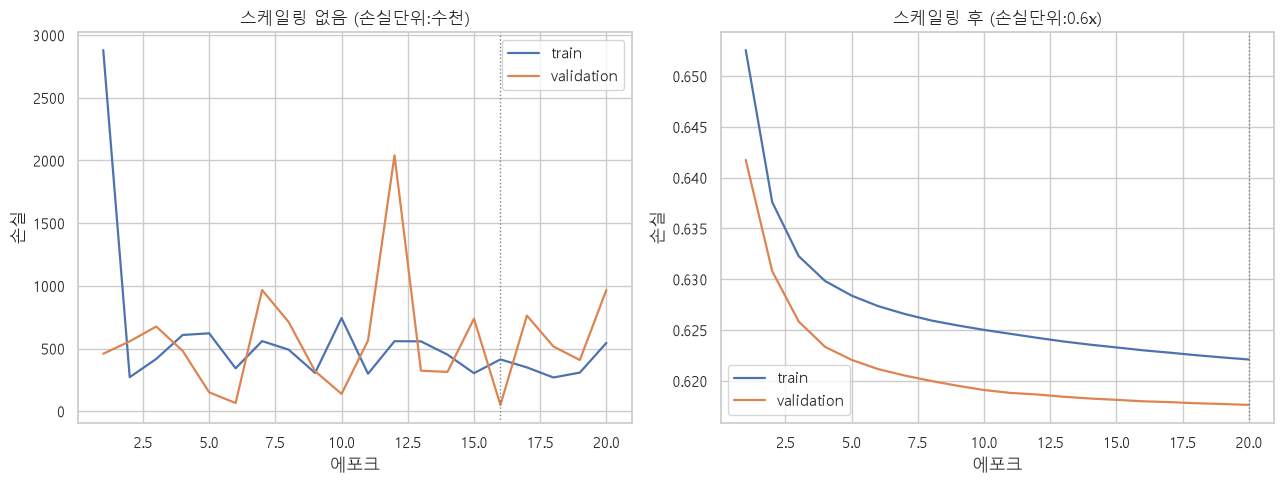

544/544 [==============================] - 0s 497us/step
스케일링 없음                      AUC 0.5031 정확도 0.6253
544/544 [==============================] - 0s 497us/step
스케일링 후                       AUC 0.6252 정확도 0.6295
AUC 비교 (스케일링 x -> o) : 0.503 -> 0.625


In [16]:
fig, axes = plt.subplots(1,2,figsize=(13,5))

plot_history(hist_raw, "스케일링 없음 (손실단위:수천)", ax=axes[0])
plot_history(hist_scaled, "스케일링 후 (손실단위:0.6x)", ax=axes[1])
plt.tight_layout()
plt.show()

auc_raw = evaluate("스케일링 없음", model_raw, X_test, y_test)
auc_scaled = evaluate("스케일링 후", model_scaled, X_test_s, y_test)

print(f"AUC 비교 (스케일링 x -> o) : {auc_raw:.3f} -> {auc_scaled:.3f}")

> 스케일링은 단순히 성능을 조금 올려주는게 아니라 



**히스토리 해석**
|모양|상태|할일|
|---|---|---|
|둘 다 내려가는 중| 학습이 되는 중|에포크를 늘림|
|둘 다 낮고 붙어있음|학습 완료 상태| 그대로 사용|
|train은 내려가는데, val은 올라감|과적합|학습 멈춤|
|둘다 높고 내려가지 않음| 과소적합, 학습데이터, 피처부족|스케일링 확인 -> 모델키우기 _>피처 추가|
|둘다 크게 튀면서 불안정||

Dropout 없이 크게 학습 -> 과적합

에포크 : 20 => 60 / 은닉층 256->256->128

In [17]:
t0 = time.time()

model_big = build_model(len(FEATURES), hidden=(256,256,128), dropout=0.0)
print(f"{model_big.count_params():,}개/ 학습 데이터{len(X_fit):,}행")

hist_big = model_scaled.fit(
    X_fit_s, y_fit, 
    epochs=60,
    batch_size=512,
    validation_data=(X_val_s, y_val),
    shuffle=False,
    verbose=0
)

print(f"학습 시간 : {time.time() - t0:.0f}초")
print_history(hist_big)

101,377개/ 학습 데이터55,968행
학습 시간 : 6초
epoch    train_loss      val_loss
    1         0.6219       0.6176
    7         0.6210       0.6174
   13         0.6202       0.6174
   19         0.6194       0.6173
   25         0.6187       0.6176
   31         0.6180       0.6179
   37         0.6173       0.6183
   43         0.6168       0.6186
   49         0.6162       0.6188
   55         0.6156       0.6191


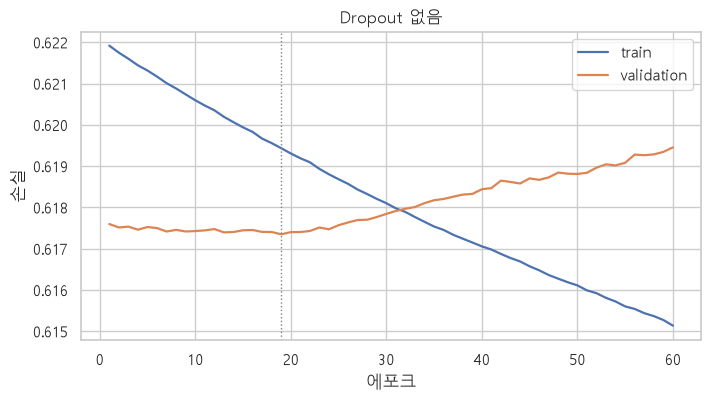

544/544 [==============================] - 0s 525us/step
은닉층 키우고 Dropout 없음           AUC 0.4709 정확도 0.3697


0.47086195357057187

In [18]:
plot_history(hist_big, "Dropout 없음")
plt.show()

evaluate("은닉층 키우고 Dropout 없음", model_big, X_test, y_test, scaler)

**과적합 신호 찾기**
- 에포크 늘리면 train 손실은 계속 내려가는데, val 손실은 어느 지점부처 올라가기 시작
- 이렇게 두 곡선이 벌어지는 모양이 "과적합"

---

### Dropout + EarlyStopping 적용

Dropout(0.3) : 학습 중 뉴런의 30%를 무작위로 끔 -> 특정 뉴런에 의존하지 못하게\
EarlyStopping : patience값 만큼 참고, 이 값이 넘어가도 검증 손실이 나아지지 않으면 멈춤

In [20]:
es = EarlyStopping(
    monitor="val_loss",     # 무엇을 볼 것인가?
    patience=8,             # 몇번 참을 것인가?
    restore_best_weights=True   # 참기 전 가장 좋았던 시점으로 되돌림
)

t0 = time.time()

model_drop = build_model(len(FEATURES), hidden=(256, 256, 128), dropout=0.3)
print(f"{model_drop.count_params():,}개 / 학습 데이터 {len(X_fit):,}행")

hist_drop = model_drop.fit(
    X_fit_s, y_fit,
    epochs=60,
    batch_size=512, 
    validation_data=(X_val_s, y_val),
    shuffle=False,
    verbose=0,
    callbacks=[es]
)

ran = len(hist_drop.history["loss"])
best = int( np.argmin(hist_drop.history['val_loss']) ) + 1

print(f"실행한 에포크 : {ran}   val_loss 최저 에포크 : {best}")

print(f"학습 시간 : {time.time() - t0:.0f}초")
print_history(hist_drop)

101,377개 / 학습 데이터 55,968행
실행한 에포크 : 30   val_loss 최저 에포크 : 22
학습 시간 : 15초
epoch    train_loss      val_loss
    1         0.6506       0.6293
    4         0.6301       0.6194
    7         0.6277       0.6182
   10         0.6258       0.6164
   13         0.6254       0.6164
   16         0.6241       0.6163
   19         0.6239       0.6163
   22         0.6238       0.6155
   25         0.6228       0.6164
   28         0.6222       0.6159


<Axes: title={'center': 'Dropout + EarlyStopping'}, xlabel='에포크', ylabel='손실'>

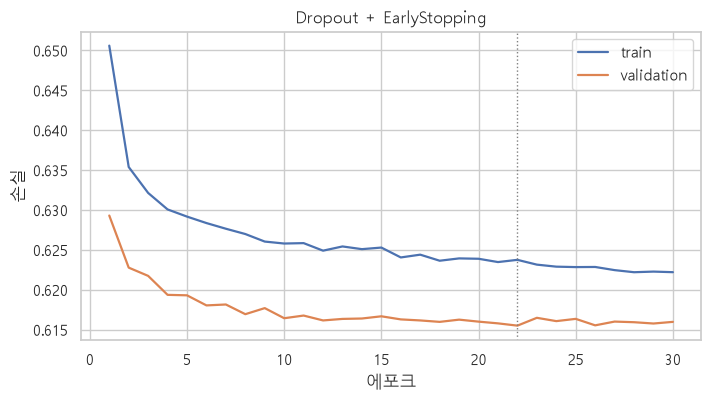

In [21]:
plot_history(hist_drop, "Dropout + EarlyStopping")